In [2]:
# Step 1: Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense

In [9]:
# Step 2: Load the Smart Grid energy consumption dataset

data = pd.read_csv("energy consumption.csv")

In [10]:
# Convert Timestamp into date-time format
data["Timestamp"] = pd.to_datetime(
    data["Timestamp"], format="%d-%m-%Y %H:%M"
)

In [11]:
# Arrange readings in chronological order
data = data.sort_values("Timestamp")

In [12]:
# Step 3: Preprocess the data to fill missing values
# Select numeric features used to learn energy consumption patterns
features = [
    "Electricity_Consumed",
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "Avg_Past_Consumption"
]

In [13]:
# Fill missing values using forward fill and backward fill
data[features] = data[features].ffill().bfill()

In [14]:
# Store the actual anomaly labels separately for evaluation
labels = data["Anomaly_Label"].values

In [15]:
# Step 4: Normalize the energy consumption data
# Scale numeric features into the range 0 to 1
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(data[features])

In [16]:
# Step 5: Create time windows for sequential input
# Each window contains 24 consecutive readings.
# The LSTM learns temporal patterns from these windows.

def create_windows(values, window_size):
    windows = []

    for i in range(len(values) - window_size + 1):
        windows.append(values[i:i + window_size])

    return np.array(windows)


window_size = 24

X = create_windows(scaled_data, window_size)

print("Window data shape:", X.shape)

Window data shape: (4977, 24, 5)


In [17]:
# Step 6: Create training and testing data
# Use windows whose readings are all labeled normal for training.
# Keep the data in chronological order.

window_labels = np.array([
    1 if np.any(labels[i:i + window_size] == 1) else 0
    for i in range(len(labels) - window_size + 1)
])

# Label 0 means normal; label 1 means anomaly.
# Train only on normal windows.
normal_windows = X[window_labels == 0]

# Split normal windows into training and validation sets
split = int(len(normal_windows) * 0.8)

X_train = normal_windows[:split]
X_val = normal_windows[split:]

# Use all windows for testing
X_test = X

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (1813, 24, 5)
Validation data shape: (454, 24, 5)
Testing data shape: (4977, 24, 5)


In [18]:
# Step 7: Build an LSTM-based Autoencoder
# Encoder learns a compact representation of each time window.
# Decoder reconstructs the original sequence.

input_layer = Input(shape=(window_size, len(features)))

# Encode temporal patterns
encoded = LSTM(64, activation="relu")(input_layer)

# Repeat encoded representation for each time step
decoded = RepeatVector(window_size)(encoded)

# Decode and reconstruct the sequence
decoded = LSTM(
    64, activation="relu", return_sequences=True
)(decoded)

# Reconstruct all five numeric features
decoded = TimeDistributed(Dense(len(features)))(decoded)

# Create the autoencoder model
autoencoder = Model(input_layer, decoded)

# Display model architecture
autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 24, 5)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          17,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 24, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 24, 5)               │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 51,269 (200.27 KB)

 Trainable params: 51,269 (200.27 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Step 8: Compile the model
# Use Adam optimizer and Mean Squared Error loss.
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

In [20]:
# Step 9: Train the model on normal energy consumption
# Input and target are the same because it is an autoencoder.
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, X_val),
    shuffle=False
)

Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.0547 - val_loss: 0.0257
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0220 - val_loss: 0.0195
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0190 - val_loss: 0.0182
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0185 - val_loss: 0.0177
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0182 - val_loss: 0.0176
Epoch 6/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0180 - val_loss: 0.0175
Epoch 7/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0179 - val_loss: 0.0174
Epoch 8/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0179 - val_loss: 0.0174
Epoch 9/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0178 - val_loss: 0.0173
Epoch 10/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0177 - val_loss: 0.0173
Epoch 11/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0176 - val_loss: 0.0172
Epoch 12/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0

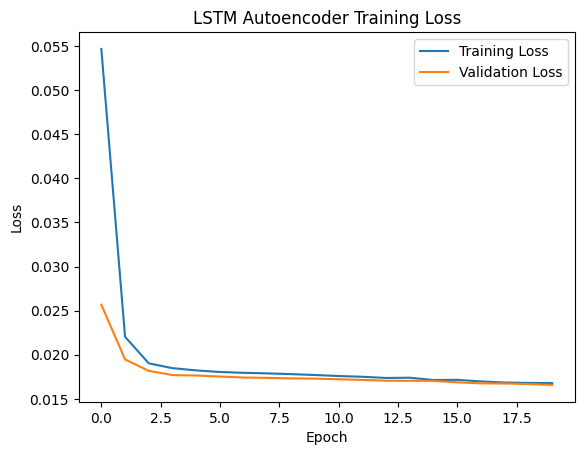

In [21]:
# Step 10: Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Autoencoder Training Loss")
plt.legend()
plt.show()


In [22]:
# Step 11: Reconstruct the testing data
reconstructed = autoencoder.predict(X_test)

156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step


In [23]:
# Step 12: Calculate reconstruction error
# Higher error indicates that the pattern is less familiar.
errors = np.mean(
    np.square(X_test - reconstructed),
    axis=(1, 2)
)

In [26]:
# Step 13: Set an error threshold
# Calculate reconstruction errors for normal validation windows.
val_reconstructed = autoencoder.predict(X_val)
val_errors = np.mean(
    np.square(X_val - val_reconstructed),
    axis=(1, 2)
)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [27]:
# Use the 95th percentile as the anomaly threshold
threshold = np.percentile(val_errors, 95)

print("Anomaly threshold:", threshold)

Anomaly threshold: 0.020846081517813184


In [28]:
# Step 14: Detect anomalies
# If reconstruction error exceeds the threshold,
# mark that time window as anomalous.
predictions = (errors > threshold).astype(int)

print("Number of detected anomalous windows:", np.sum(predictions))

Number of detected anomalous windows: 601


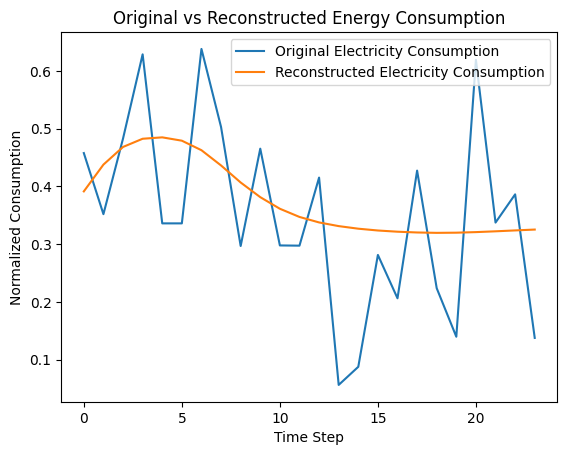

In [29]:
# Step 15: Visualize original and reconstructed consumption
# Plot the electricity consumption feature for one test window.
i = 0

plt.plot(
    X_test[i, :, 0],
    label="Original Electricity Consumption"
)

plt.plot(
    reconstructed[i, :, 0],
    label="Reconstructed Electricity Consumption"
)

plt.xlabel("Time Step")
plt.ylabel("Normalized Consumption")
plt.title("Original vs Reconstructed Energy Consumption")
plt.legend()
plt.show()


In [30]:
# Step 16: Display the result for one window
print("Reconstruction Error:", errors[i])

if predictions[i] == 1:
    print("Anomaly Detected")
else:
    print("Normal Energy Consumption")

Reconstruction Error: 0.014952885433446285
Normal Energy Consumption
